<a href="https://colab.research.google.com/github/moatazaldahni-stack/Polynomial-Regression-Optimizers/blob/main/5_Adam_Optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

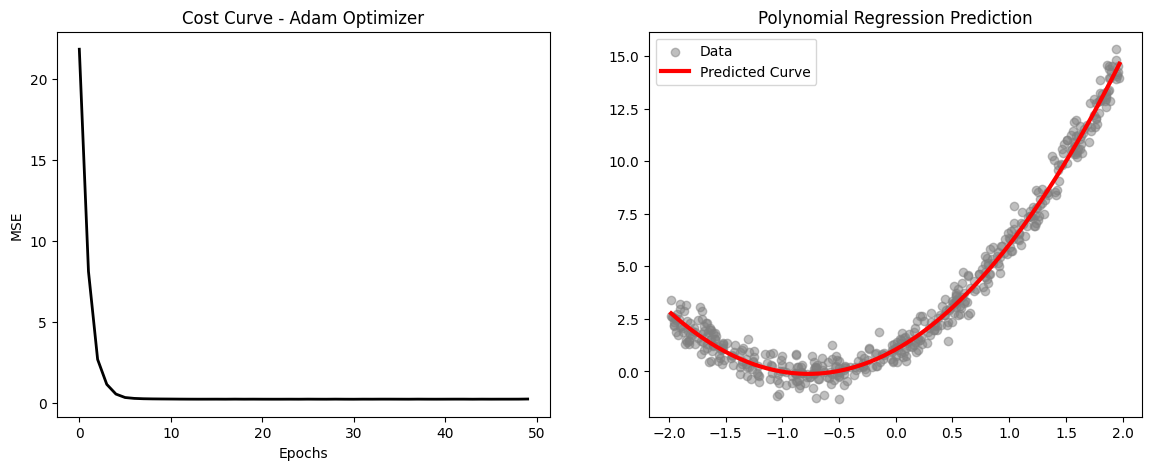

In [10]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)
m = 500
X = np.random.rand(m, 1) * 4 - 2
y = 2 * (X**2) + 3 * X + 1 + np.random.randn(m, 1) * 0.5

X_poly = np.c_[np.ones((m, 1)), X, X**2]


epochs = 50
lr = 0.05
beta1 = 0.9
beta2 = 0.999
eps = 1e-8
batch_size = 32

w = np.random.randn(3, 1) * 0.01
v = np.zeros_like(w)
s = np.zeros_like(w)
t = 0
losses = []


for epoch in range(epochs):
    epoch_loss = 0


    indices = np.random.permutation(m)
    X_shuffled, y_shuffled = X_poly[indices], y[indices]

    num_batches = 0
    for i in range(0, m, batch_size):
        Xi = X_shuffled[i:i+batch_size]
        yi = y_shuffled[i:i+batch_size]

        predictions = Xi.dot(w)
        error = predictions - yi
        grad = (2/len(Xi)) * Xi.T.dot(error)
        t += 1


        v = beta1 * v + (1 - beta1) * grad
        s = beta2 * s + (1 - beta2) * (grad**2)


        v_hat = v / (1 - beta1**t)
        s_hat = s / (1 - beta2**t)


        w = w - (lr / (np.sqrt(s_hat) + eps)) * v_hat

        epoch_loss += np.mean(error**2)
        num_batches += 1

    losses.append(epoch_loss / num_batches)


plt.figure(figsize=(14, 5))


plt.subplot(1, 2, 1)
plt.plot(losses, color='black', linewidth=2)
plt.title('Cost Curve - Adam Optimizer')
plt.xlabel('Epochs')
plt.ylabel('MSE')


plt.subplot(1, 2, 2)
sorted_idx = np.argsort(X.flatten())
plt.scatter(X, y, color='gray', alpha=0.5, label='Data')
plt.plot(X[sorted_idx], X_poly[sorted_idx].dot(w), color='red', linewidth=3, label='Predicted Curve')
plt.title('Polynomial Regression Prediction')
plt.legend()

plt.show()

